# $\pi/\sqrt3$: historical CMF bounds

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, y0 = sp.symbols('x0 x1 y0')
target = lambda: arb.pi()/arb(3).sqrt()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Alladi–Robinson (1980): $\pi/\sqrt3$

[Quadratic integral and measure formula](https://www.math.ru.nl/~wzudilin/gat/oALLADI4.txt).


$$E_n=\int_0^1\frac{t^n(1-t)^n}{(t^2+3)^{n+1}}\,dt.$$
**CMF:** rank 2, ${}_2F_1(-1/3)$ · **Start:** $(1/2,1;3/2)$ · **Direction:** $(1,1;2)$. One step advances the source index by two; the plotted samples use $N/2$ steps.
With $c=\arctan(1/\sqrt{3})/\sqrt{3}$, $E_n=C_n+B_nc$ and $p_n/q_n=-6C_n/B_n$. The source labels $c$ differently; the integral fixes its value. The displayed measure formula also uses its denominator lemma.
The exact identity
$$E_n=\frac{(n!)^2}{(2n+1)!\,3^{n+1}}{}_2F_1\!\left(\frac{n+1}{2},\frac{n+2}{2};n+\frac32;-\frac1{3}\right)$$
follows by expanding the quadratic denominator and cancelling an equal upper and lower parameter. The common scalar cancels in the rational readout.

In [5]:
cmf = pFq(2, 1, -sp.Rational(1, 3))
start = {x0: sp.Rational(1, 2), x1: 1, y0: sp.Rational(3, 2)}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, [N // 2 for N in DEPTHS], start)
approximants = [-6 * M[1, 0] / (4 * (2 * M[0, 0] - M[1, 0])) for M in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Alladi–Robinson (1980)'] = (DEPTHS, deltas)
accuracy['Alladi–Robinson (1980)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.151972672092


## 2. Hata (1993): three-root integral

[Theorem 1.2 and Section 4, pp. 337, 345-347](https://matwbn.icm.edu.pl/ksiazki/aa/aa63/aa6344.pdf).

**CMF:** rank 3, ${}_3F_2(-1/3)$; **Start:** $(1/2,1,1/2;1/2,3/2)$; **Direction:** $(3,3,2;0,6)$.
After setting $t=ix/\sqrt3$ and taking the even part on $[-1,1]$, the source integral is a common nonzero scalar times
$${}_3F_2\!\left(\frac{3n+1}{2},\frac{3n+2}{2},n+\frac12;\frac12,3n+\frac32;-\frac13\right).$$
Thus $N/2$ steps give the sampled even source indices $n=N$, including exactly $n=500$.
In the $(F,\theta F,\theta^2F)$ basis, use $C=(0,12,-9)$ and $B=(16,-8,4)$.
The readout is $p_N/q_N=-(CM)_0/(BM)_0$.

Even source indices N use N/2 CMF steps.

In [7]:
x2, y1 = sp.symbols('x2 y1')
cmf = pFq(3, 2, -sp.Rational(1, 3))
start = {x0: sp.Rational(1, 2), x1: 1, x2: sp.Rational(1, 2), y0: sp.Rational(1, 2), y1: sp.Rational(3, 2)}
trajectory = {x0: 3, x1: 3, x2: 2, y0: 0, y1: 6}
walks = cmf.walk(trajectory, [N // 2 for N in DEPTHS], start)
C = Matrix([[0, 12, -9]])
B = Matrix([[16, -8, 4]])
approximants = [-(C * M)[0] / (B * M)[0] for M in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Hata (1993)'] = (DEPTHS, deltas)
accuracy['Hata (1993)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.284437567262


## 3. Heimonen–Matala-aho–Väänänen (1994): $\beta=3/2$

[Jacobi Padé construction, §§3–4 and examples](https://www.cambridge.org/core/services/aop-cambridge-core/content/view/249C98E58A8F5967C24F7999398BDBCE/S0004972700013691a.pdf/an-application-of-jacobi-type-polynomials-to-irrationality-measures.pdf).

 The published bound is $\mu_0=5.0874\ldots$.
Let $F(z)={}_2F_1(1,\tfrac12;\tfrac32;z)$ and $m=\lfloor(3/2)n\rfloor$. The Padé remainder is proportional to
$$J_0(n-\tfrac12,m,n+1)=\int_0^1 \frac{t^{n-1/2}(1-t)^m}{(1+t/3)^{n+1}}\,dt.$$
**CMF:** rank 2, ${}_2F_1(-1/3)$ · **Start:** $(3,5/2;13/2)$, source $(n,m)=(2,3)$ · **Direction:** $(2,2;5)$. The code gives the coefficient rows in the $(F,\theta F)$ basis; the target readout is $-2(CM)_0/(BM)_0$.
Euler integration gives $J_0=B(U+1,V+1){}_2F_1(W,U+1;U+V+2;-1/a)$. The beta factor cancels in the readout.

Source index N = 2 + 2k; the sampled even indices use (N − 2)/2 steps.

In [9]:
cmf = pFq(2, 1, -sp.Rational(1, 3))
start = {x0: 3, x1: sp.Rational(5, 2), y0: sp.Rational(13, 2)}
C = Matrix([[-sp.Rational(28404, 5), sp.Rational(287469, 10)]])
B = Matrix([[6264, -31698]])
trajectory = {x0: 2, x1: 2, y0: 5}
walks = cmf.walk(trajectory, [(N - 2) // 2 for N in DEPTHS], start)
approximants = [-2 * (C * M)[0] / (B * M)[0] for M in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Heimonen–Matala-aho–Väänänen (1994)'] = (DEPTHS, deltas)
accuracy['Heimonen–Matala-aho–Väänänen (1994)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.248525038543


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

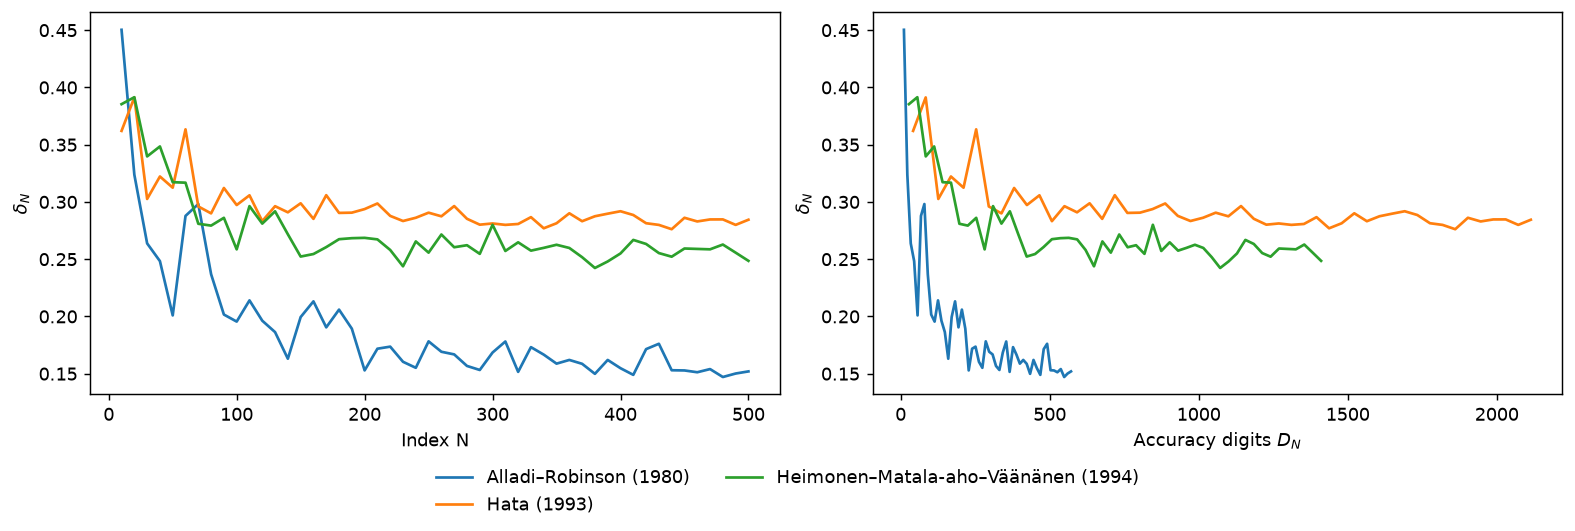

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [13]:
bounds = {
    'Alladi–Robinson (1980)': '8.309986340',
    'Hata (1993)': '$4.601579125506\\ldots$',
    'Heimonen–Matala-aho–Väänänen (1994)': '$5.0874\\ldots$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Alladi–Robinson (1980) | 8.309986340 | 0.151972672092 (N = 500) |
| Hata (1993) | $4.601579125506\ldots$ | 0.284437567262 (N = 500) |
| Heimonen–Matala-aho–Väänänen (1994) | $5.0874\ldots$ | 0.248525038543 (N = 500) |